# Underfitting in Neural Networks

**Goal of this notebook:** understand what underfitting looks like, why it happens, and how to fix it, using a small PyTorch training loop you can read line by line.

By the end you should be able to:

1. Recognise underfitting from loss/accuracy curves and from the decision boundary.
2. Name the four common causes (too little capacity, missing non-linearity, too little optimisation, too much regularisation).
3. Run a controlled experiment for each cause and apply the matching fix.

**What is underfitting?**
A model underfits when it is too simple, or too constrained, or too under-trained, to capture the pattern in the data. It performs poorly on the **training** set itself, so it also performs poorly on new data. This is a *high bias* problem.

```
                 Training error   Validation error   Gap
Underfitting      HIGH             HIGH               small    <-- this notebook
Good fit          low              low                small
Overfitting       low              HIGH               large
```

The key difference from overfitting: in overfitting, training error is low. In underfitting, **training error is already bad**, so adding more data or more regularisation will not help.

## 1. Setup

In [1]:
import random
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader, random_split
import matplotlib.pyplot as plt

SEED = 42


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


set_seed()
device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch:", torch.__version__, "| device:", device)

PyTorch: 2.15.0+cu132 | device: cpu


## 2. The dataset: two intertwined spirals

We need a problem where underfitting is easy to *see*. Two spirals is the classic choice:

- 2 input features (x, y) so we can draw the decision boundary.
- 2 classes that are **not linearly separable**, so a straight line cannot solve it, but a small neural network can.

A model that scores ~50% here is no better than a coin flip, and a straight line only manages about 60%.

X: torch.Size([1000, 2]) y: torch.Size([1000]) | class balance: [500, 500]


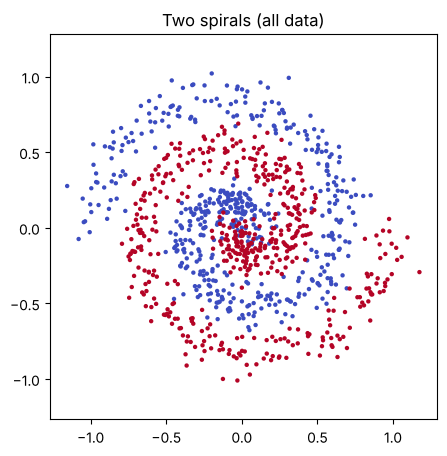

In [2]:
def make_spiral(n_per_class=500, turns=1.5, noise=0.08, seed=0):
    """Two interleaved spirals. Returns X (N,2) float32 and y (N,) int64."""
    rng = np.random.RandomState(seed)
    t = np.linspace(0.05, 1.0, n_per_class)
    theta = t * turns * 2 * np.pi
    xs, ys = [], []
    for cls in (0, 1):
        ang = theta + cls * np.pi
        x = t * np.cos(ang) + rng.randn(n_per_class) * noise
        y = t * np.sin(ang) + rng.randn(n_per_class) * noise
        xs.append(np.stack([x, y], axis=1))
        ys.append(np.full(n_per_class, cls))
    X = np.concatenate(xs).astype(np.float32)
    y = np.concatenate(ys).astype(np.int64)
    return torch.from_numpy(X), torch.from_numpy(y)


X, y = make_spiral()
print("X:", X.shape, "y:", y.shape, "| class balance:", y.bincount().tolist())

plt.figure(figsize=(5, 5))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", s=10, edgecolor="none")
plt.title("Two spirals (all data)")
plt.axis("equal")
plt.show()

In [3]:
# 80/20 train/validation split
n_train = int(0.8 * len(X))
train_ds, val_ds = random_split(
    TensorDataset(X, y), [n_train, len(X) - n_train],
    generator=torch.Generator().manual_seed(SEED),
)

X_tr, y_tr = X[train_ds.indices].to(device), y[train_ds.indices].to(device)
X_val, y_val = X[val_ds.indices].to(device), y[val_ds.indices].to(device)

train_loader = DataLoader(train_ds, batch_size=64, shuffle=True)
print(f"train: {len(train_ds)} samples, val: {len(val_ds)} samples")

train: 800 samples, val: 200 samples


## 3. The training loop (reusable)

The same five steps you already know, wrapped so we can run many experiments with one call:

1. `optimizer.zero_grad()`
2. forward pass
3. compute loss
4. `loss.backward()`
5. `optimizer.step()`

After each epoch we evaluate **both** the training set and the validation set in `eval` mode. Comparing these two numbers is the whole diagnostic.

In [4]:
criterion = nn.CrossEntropyLoss()


@torch.no_grad()
def evaluate(model, X_, y_):
    model.eval()
    logits = model(X_)
    loss = criterion(logits, y_).item()
    acc = (logits.argmax(dim=1) == y_).float().mean().item()
    return loss, acc


def fit(model, optimizer, epochs, verbose_every=0):
    """Train `model` and return a history dict of per-epoch metrics."""
    model.to(device)
    hist = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    for epoch in range(1, epochs + 1):
        model.train()
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()            # 1. clear old gradients
            loss = criterion(model(xb), yb)  # 2-3. forward + loss
            loss.backward()                  # 4. backprop
            optimizer.step()                 # 5. update weights

        tl, ta = evaluate(model, X_tr, y_tr)
        vl, va = evaluate(model, X_val, y_val)
        for k, v in zip(hist, (tl, ta, vl, va)):
            hist[k].append(v)
        if verbose_every and epoch % verbose_every == 0:
            print(f"epoch {epoch:4d} | train loss {tl:.4f} acc {ta:.3f} | val loss {vl:.4f} acc {va:.3f}")
    return hist

### Plotting helpers

Two views, and you should always look at both:

- **Learning curves** (loss and accuracy vs epoch, train and val).
- **Decision boundary** (what the model has actually learned).

In [5]:
def plot_curves(hist, title=""):
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
    ep = range(1, len(hist["train_loss"]) + 1)
    ax[0].plot(ep, hist["train_loss"], label="train")
    ax[0].plot(ep, hist["val_loss"], label="val", linestyle="--")
    ax[0].set_title("Loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
    ax[1].plot(ep, hist["train_acc"], label="train")
    ax[1].plot(ep, hist["val_acc"], label="val", linestyle="--")
    ax[1].axhline(0.5, color="gray", linewidth=0.8, linestyle=":")
    ax[1].set_ylim(0.4, 1.02)
    ax[1].set_title("Accuracy (dotted = coin flip)"); ax[1].set_xlabel("epoch"); ax[1].legend()
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


@torch.no_grad()
def plot_boundary(model, ax=None, title=""):
    model.eval().to(device)
    show = ax is None
    if show:
        _, ax = plt.subplots(figsize=(4.5, 4.5))
    gx, gy = np.meshgrid(np.linspace(-1.3, 1.3, 250), np.linspace(-1.3, 1.3, 250))
    grid = torch.tensor(np.c_[gx.ravel(), gy.ravel()], dtype=torch.float32, device=device)
    pred = model(grid).argmax(dim=1).cpu().numpy().reshape(gx.shape)
    ax.contourf(gx, gy, pred, alpha=0.3, cmap="coolwarm")
    ax.scatter(X_tr.cpu()[:, 0], X_tr.cpu()[:, 1], c=y_tr.cpu(), cmap="coolwarm", s=6, edgecolor="none")
    ax.set_title(title, fontsize=9)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_aspect("equal")
    if show:
        plt.show()

## 4. A first underfitting model: logistic regression

The simplest possible network: one `Linear(2, 2)` layer. It can only draw a **straight line**.

In [6]:
set_seed()
linear = nn.Sequential(nn.Linear(2, 2))
opt = torch.optim.Adam(linear.parameters(), lr=0.01)
hist_linear = fit(linear, opt, epochs=150, verbose_every=30)

epoch   30 | train loss 0.6586 acc 0.615 | val loss 0.6617 acc 0.635


epoch   60 | train loss 0.6586 acc 0.615 | val loss 0.6613 acc 0.635


epoch   90 | train loss 0.6586 acc 0.613 | val loss 0.6635 acc 0.620


epoch  120 | train loss 0.6586 acc 0.613 | val loss 0.6628 acc 0.625
epoch  150 | train loss 0.6586 acc 0.613 | val loss 0.6614 acc 0.630


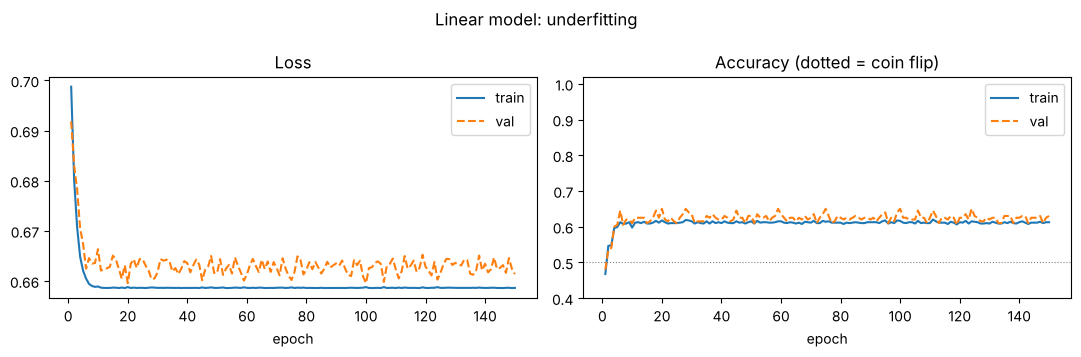

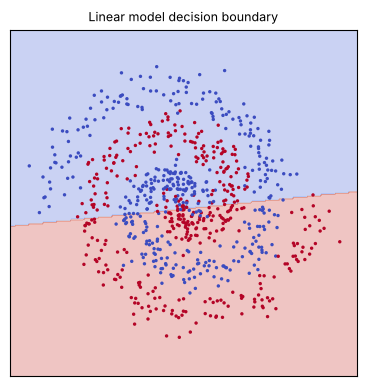

In [7]:
plot_curves(hist_linear, "Linear model: underfitting")
plot_boundary(linear, title="Linear model decision boundary")

### How to read this

- **Training accuracy is only ~60%** (a coin flip is 50%). The model cannot even fit the data it was trained on. That is the signature of underfitting.
- **Train and validation curves sit on top of each other.** There is no generalisation gap, so this is *not* overfitting.
- **The loss flattens early** and stays high. More epochs will not help, because the model has hit the ceiling of what a straight line can do.
- **The boundary is a straight line** slicing through two spirals.

> **Rule of thumb:** if training performance is bad, you have a bias problem. Do not reach for more data or more regularisation. Make the model more expressive or optimise it better.

## 5. Reference: a model that does *not* underfit

Before exploring causes, let's train a healthy baseline so we have something to compare against. Same data, same loop. We only change the model: two hidden layers of 64 units with ReLU.

In [8]:
def make_mlp(hidden=64, layers=2, act=nn.ReLU):
    mods, d = [], 2
    for _ in range(layers):
        mods += [nn.Linear(d, hidden), act()]
        d = hidden
    mods.append(nn.Linear(d, 2))
    return nn.Sequential(*mods)


set_seed()
good = make_mlp(hidden=64, layers=2)
opt = torch.optim.Adam(good.parameters(), lr=0.01)
hist_good = fit(good, opt, epochs=200, verbose_every=50)

epoch   50 | train loss 0.1234 acc 0.951 | val loss 0.1578 acc 0.935


epoch  100 | train loss 0.1208 acc 0.940 | val loss 0.1396 acc 0.955


epoch  150 | train loss 0.1090 acc 0.954 | val loss 0.1617 acc 0.930


epoch  200 | train loss 0.0992 acc 0.952 | val loss 0.1644 acc 0.925


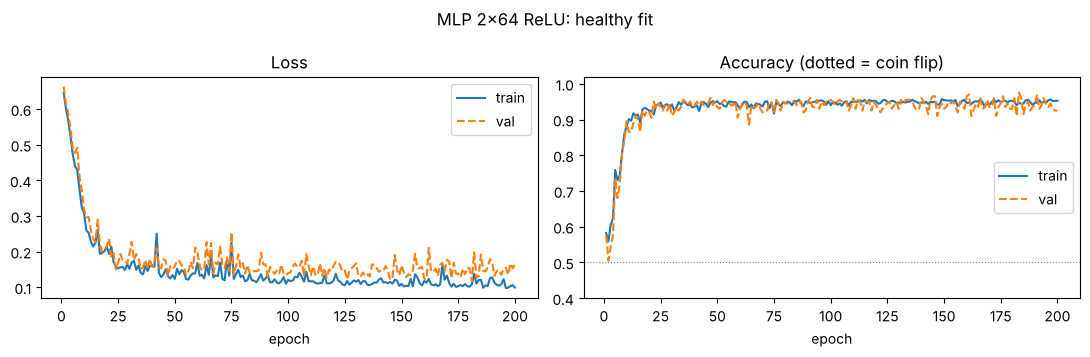

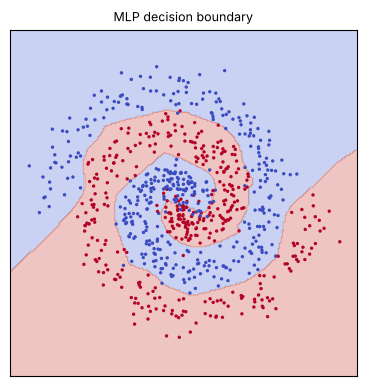

In [9]:
plot_curves(hist_good, "MLP 2x64 ReLU: healthy fit")
plot_boundary(good, title="MLP decision boundary")

Now both train and validation accuracy are high, and the boundary follows the spiral arms. Every experiment below is a **deliberately broken** version of this model.

## 6. Four causes of underfitting (and a controlled experiment for each)

| # | Cause | What we change from the healthy model |
|---|-------|--------------------------------------|
| A | **Too little capacity** | Hidden layer shrunk to 2 units |
| B | **No non-linearity** | Remove the ReLUs (a deep *linear* network) |
| C | **Too little optimisation** | Tiny learning rate and very few epochs |
| D | **Too much regularisation** | Huge weight decay |

For each we keep the data, loop, and everything else fixed so the only difference is the cause.

In [10]:
def build_and_train(cause):
    set_seed()
    if cause == "A: tiny capacity":
        model = make_mlp(hidden=2, layers=1)
        opt = torch.optim.Adam(model.parameters(), lr=0.01); epochs = 200
    elif cause == "B: no non-linearity":
        model = nn.Sequential(nn.Linear(2, 64), nn.Linear(64, 64), nn.Linear(64, 2))  # 3 layers, no activations
        opt = torch.optim.Adam(model.parameters(), lr=0.01); epochs = 200
    elif cause == "C: too little training":
        model = make_mlp(hidden=64, layers=2)
        opt = torch.optim.Adam(model.parameters(), lr=1e-4); epochs = 5
    elif cause == "D: over-regularised":
        model = make_mlp(hidden=64, layers=2)
        opt = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=1.0); epochs = 200
    return model, fit(model, opt, epochs)


causes = ["A: tiny capacity", "B: no non-linearity", "C: too little training", "D: over-regularised"]
underfit_runs = {c: build_and_train(c) for c in causes}

print(f"{'run':26s} {'train acc':>10s} {'val acc':>9s} {'train loss':>11s}")
print("-" * 60)
for name, h in [("Healthy MLP (reference)", hist_good), ("Linear model", hist_linear)] + \
               [(c, r[1]) for c, r in underfit_runs.items()]:
    print(f"{name:26s} {h['train_acc'][-1]:10.3f} {h['val_acc'][-1]:9.3f} {h['train_loss'][-1]:11.3f}")

run                         train acc   val acc  train loss
------------------------------------------------------------
Healthy MLP (reference)         0.952     0.925       0.099
Linear model                    0.613     0.630       0.659
A: tiny capacity                0.615     0.650       0.658
B: no non-linearity             0.610     0.625       0.659
C: too little training          0.585     0.625       0.681
D: over-regularised             0.516     0.435       0.693


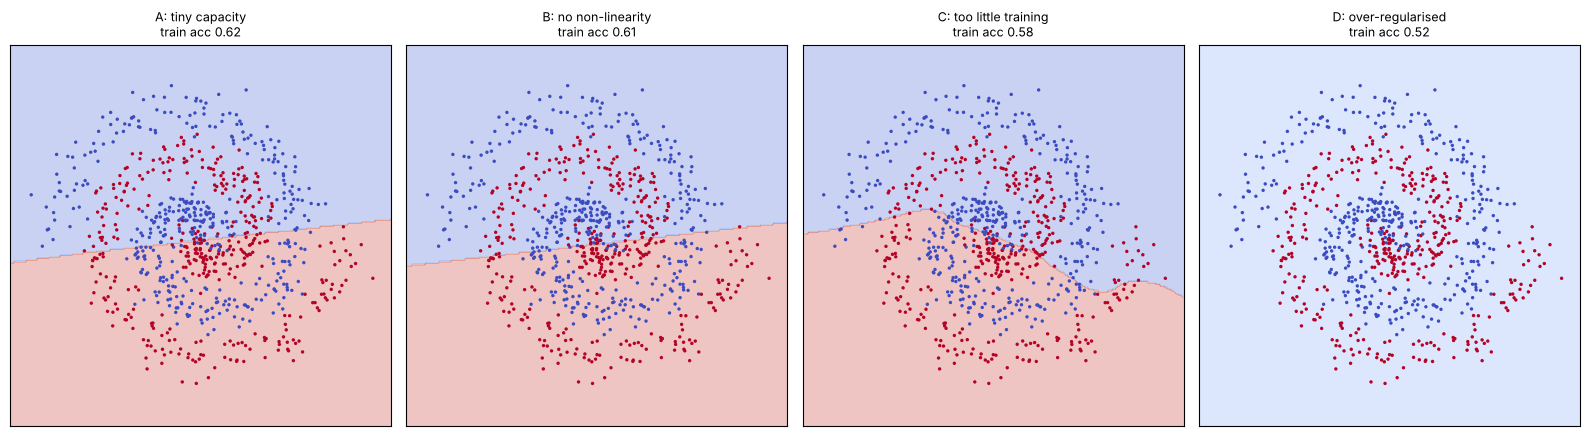

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4.2))
for ax, (name, (model, h)) in zip(axes, underfit_runs.items()):
    plot_boundary(model, ax=ax, title=f"{name}\ntrain acc {h['train_acc'][-1]:.2f}")
plt.tight_layout()
plt.show()

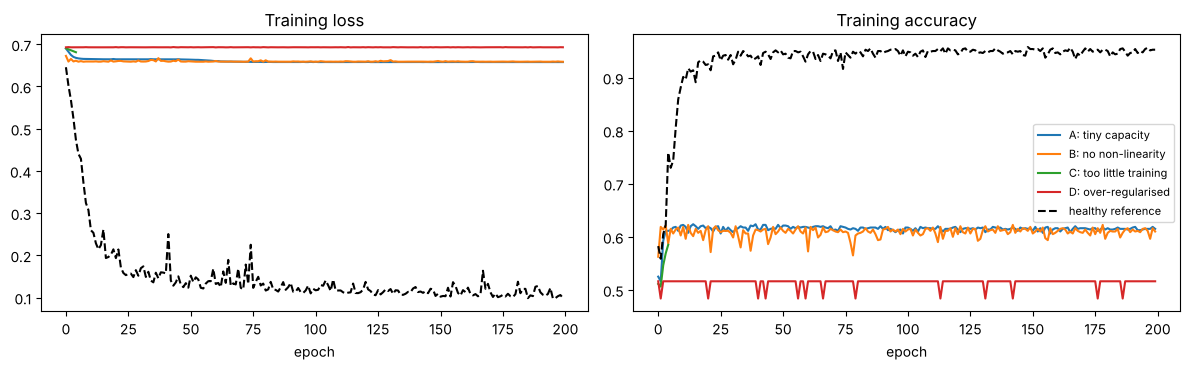

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for name, (_, h) in underfit_runs.items():
    ax[0].plot(h["train_loss"], label=name)
    ax[1].plot(h["train_acc"], label=name)
ax[0].plot(hist_good["train_loss"], "k--", label="healthy reference")
ax[1].plot(hist_good["train_acc"], "k--", label="healthy reference")
ax[0].set_title("Training loss"); ax[1].set_title("Training accuracy")
ax[0].set_xlabel("epoch"); ax[1].set_xlabel("epoch"); ax[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

### What each failure looks like

- **A. Tiny capacity.** Two hidden units can only bend the boundary a little. It ends up barely better than the straight line and cannot trace a spiral.
- **B. No non-linearity.** This is the most instructive one. The network has 3 layers and thousands of parameters, yet it behaves exactly like the linear model. Stacking linear layers collapses to a single linear map: `W3(W2(W1 x)) = W x`. **Depth without activation functions adds no expressive power.**
- **C. Too little training.** The architecture is fine, but the optimiser has not had time (or a big enough step size) to get anywhere. The loss is still sloping downward when we stop. This is the one case where "train longer" is the cure.
- **D. Over-regularisation.** Weight decay pulls weights toward zero harder than the data can push them away. The model collapses toward a constant prediction. Regularisation is meant to fight overfitting, but too much of it *causes* underfitting.

Note that curve shape separates the causes: A and B plateau, C is still improving when it stops, and D never gets going.

## 7. Fixing underfitting

The cure follows the diagnosis. Here is a checklist in the order you should try it:

```
Training accuracy/loss is poor
        |
        v
Is the loss still dropping when training stops?
   |-- yes --> train longer / raise learning rate / use a better optimiser   (cause C)
   |-- no  --> continue
        |
        v
Are there activation functions between layers?
   |-- no  --> add non-linearities (ReLU, GELU, ...)                         (cause B)
   |-- yes --> continue
        |
        v
Is weight decay / dropout / other regularisation strong?
   |-- yes --> reduce it                                                     (cause D)
   |-- no  --> continue
        |
        v
Increase capacity: wider layers, more layers, or better input features       (cause A)
```

In [13]:
fixes = {
    "A -> wider (2 -> 64 units)":        ("A: tiny capacity",        lambda: (make_mlp(hidden=64, layers=1), 0.01, 0.0, 200)),
    "B -> add ReLU activations":         ("B: no non-linearity",     lambda: (make_mlp(hidden=64, layers=2), 0.01, 0.0, 200)),
    "C -> lr 1e-4 -> 1e-2, 5 -> 200 ep": ("C: too little training",  lambda: (make_mlp(hidden=64, layers=2), 0.01, 0.0, 200)),
    "D -> weight decay 1.0 -> 0":        ("D: over-regularised",     lambda: (make_mlp(hidden=64, layers=2), 0.01, 0.0, 200)),
}

fixed_runs = {}
for label, (_, cfg) in fixes.items():
    set_seed()
    model, lr, wd, epochs = cfg()
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
    fixed_runs[label] = (model, fit(model, opt, epochs))

print(f"{'fix':36s} {'before (train)':>15s} {'after (train)':>14s} {'after (val)':>12s}")
print("-" * 80)
for label, (cause, _) in fixes.items():
    before = underfit_runs[cause][1]["train_acc"][-1]
    after = fixed_runs[label][1]
    print(f"{label:36s} {before:15.3f} {after['train_acc'][-1]:14.3f} {after['val_acc'][-1]:12.3f}")

fix                                   before (train)  after (train)  after (val)
--------------------------------------------------------------------------------
A -> wider (2 -> 64 units)                     0.615          0.942        0.930
B -> add ReLU activations                      0.610          0.952        0.925
C -> lr 1e-4 -> 1e-2, 5 -> 200 ep              0.585          0.952        0.925
D -> weight decay 1.0 -> 0                     0.516          0.952        0.925


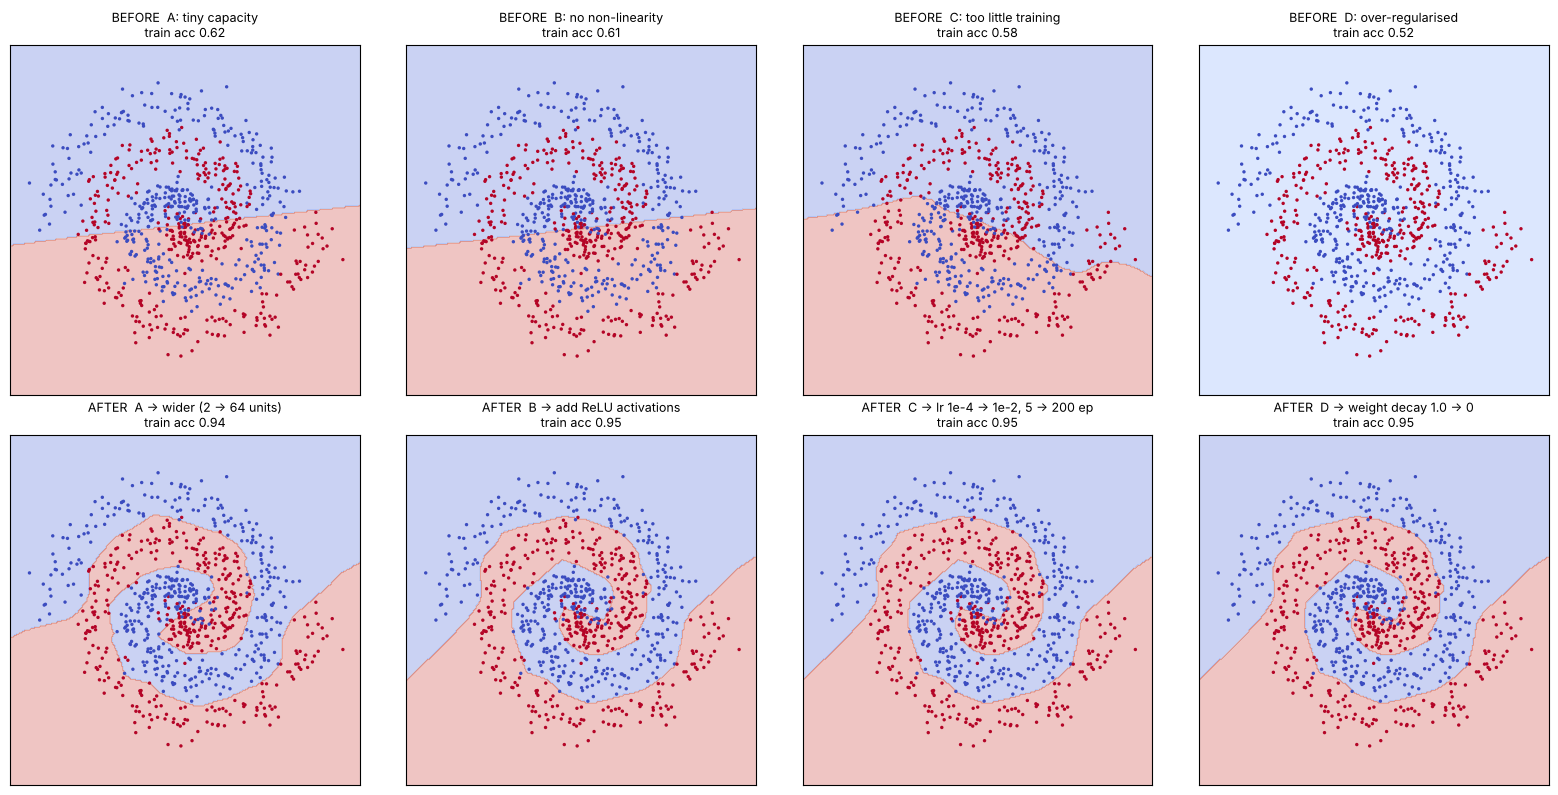

In [14]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for col, ((label, (cause, _)), _) in enumerate(zip(fixes.items(), range(4))):
    m_bad, h_bad = underfit_runs[cause]
    m_ok, h_ok = fixed_runs[label]
    plot_boundary(m_bad, ax=axes[0, col], title=f"BEFORE  {cause}\ntrain acc {h_bad['train_acc'][-1]:.2f}")
    plot_boundary(m_ok, ax=axes[1, col], title=f"AFTER  {label}\ntrain acc {h_ok['train_acc'][-1]:.2f}")
plt.tight_layout()
plt.show()

## 8. Capacity sweep: watching underfitting fade

A cleaner way to see underfitting is to sweep one knob and plot the result. Here we vary only the **hidden width** of a single-hidden-layer ReLU network, and record final train and validation accuracy.

width    1 | train acc 0.572 | val acc 0.625


width    2 | train acc 0.615 | val acc 0.650


width    3 | train acc 0.604 | val acc 0.605


width    4 | train acc 0.627 | val acc 0.630


width    8 | train acc 0.776 | val acc 0.720


width   16 | train acc 0.761 | val acc 0.715


width   32 | train acc 0.924 | val acc 0.905


width   64 | train acc 0.942 | val acc 0.930


width  128 | train acc 0.956 | val acc 0.940


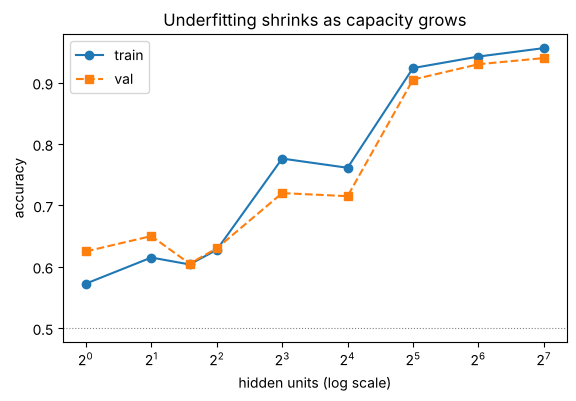

In [15]:
widths = [1, 2, 3, 4, 8, 16, 32, 64, 128]
sweep = {"train": [], "val": []}
for w in widths:
    set_seed()
    m = make_mlp(hidden=w, layers=1)
    h = fit(m, torch.optim.Adam(m.parameters(), lr=0.01), epochs=200)
    sweep["train"].append(h["train_acc"][-1])
    sweep["val"].append(h["val_acc"][-1])
    print(f"width {w:4d} | train acc {sweep['train'][-1]:.3f} | val acc {sweep['val'][-1]:.3f}")

plt.figure(figsize=(6.5, 4))
plt.plot(widths, sweep["train"], "o-", label="train")
plt.plot(widths, sweep["val"], "s--", label="val")
plt.xscale("log", base=2)
plt.axhline(0.5, color="gray", linestyle=":", linewidth=0.8)
plt.xlabel("hidden units (log scale)"); plt.ylabel("accuracy")
plt.title("Underfitting shrinks as capacity grows")
plt.legend()
plt.show()

On the left, **train and validation accuracy are both low and close together**: underfitting. As width grows, both climb together. If you kept going into much larger models on a small dataset you would eventually see train accuracy keep rising while validation stalls, which is the start of overfitting. The sweet spot is the smallest model whose *training* accuracy is already good.

## 9. Key takeaways

1. **Diagnose with training metrics first.** Poor training loss/accuracy means underfitting, regardless of the validation numbers.
2. **A small train-validation gap does not mean "good".** Both can be equally bad. Always compare against a known-good reference or a sensible baseline (here, 50% chance).
3. **Four usual suspects:** too little capacity, no non-linearity, too little optimisation, too much regularisation.
4. **Depth needs non-linearity.** Stacked linear layers are still one linear layer.
5. **Curve shape tells you which cause:** plateau means the model is limited, still-falling means train longer, flat from the start means regularisation or learning-rate trouble.
6. **Fix bias with a more expressive model or better optimisation,** not with more data or more regularisation.

## 10. Exercises

1. In experiment C, keep `lr=1e-4` but raise epochs until training accuracy matches the healthy model. How many epochs does it take? What does that say about learning rate vs training time?
2. In experiment D, sweep `weight_decay` over `[0, 1e-4, 1e-3, 1e-2, 1e-1, 1.0]` and plot final train and validation accuracy. Where does the model switch from healthy to underfit?
3. Replace `nn.ReLU` with `nn.Tanh` or `nn.GELU` in `make_mlp`. Does the capacity sweep change?
4. Add a dropout layer with `p=0.9` after each hidden layer. Which cause (A-D) does it resemble?
5. Increase `turns` in `make_spiral` to 3 to make the problem harder. Does the 2x64 network still fit it? If not, which fix from Section 7 repairs it?
6. **Feature engineering.** Add the radius `r = sqrt(x^2 + y^2)` and angle `atan2(y, x)` as extra input features to the linear model. Does a linear model still underfit?